# RAG over a Board-Game Rulebook: Bi-Encoder Baseline vs. Cross-Encoder Re-Ranking

**Document:** *Brass: Birmingham* rulebook (Roxley Games, v2018.11, 12 pages), `doc.pdf`.
It is dense with exceptions ("except when…"), era-specific restrictions and cross-references, which makes it a good stress test for retrieval.

**Every model runs locally from the Hugging Face Hub. No API calls are made.**

| Role | Model | Size |
|---|---|---|
| Bi-encoder (dense retrieval) | `sentence-transformers/all-MiniLM-L6-v2` | 22.7M params |
| Cross-encoder (re-ranker) | `cross-encoder/ms-marco-MiniLM-L-6-v2` | 22.7M params |
| Generator LLM | `Qwen/Qwen3-4B-Instruct-2507` | 4.0B params |

**The two pipelines share one chunked corpus and one prompt template:**

```
Pipeline 1 (baseline):   query ─► bi-encoder ─► FAISS top-10 (cosine) ─► top-3 ───────────────────────────────► LLM ─► Answer 1
Pipeline 2 (re-ranking): query ─► bi-encoder ─► FAISS top-10 (cosine) ─► cross-encoder on 10 pairs ─► top-3 ─► LLM ─► Answer 2
```

**Contents:**
1. Setup & environment
2. Load and parse the PDF
3. Chunking
4. Pipeline 1: bi-encoder + FAISS
5. Pipeline 2: cross-encoder re-ranking
6. Generator LLM and the shared prompt
7. Sanity check
8. Failure-mode analysis (stress tests)
9. Broader check over 76 labelled questions
10. Latency profiling
11. Scaling experiment
12. Export results

## 1. Setup & environment

The first run downloads about 8.5 GB of model weights from the Hugging Face Hub, which are cached after that.
A GPU is recommended; this notebook was run on an NVIDIA RTX 5060 Ti (16 GB).
On CPU everything still works, but generation with the 4B LLM is slow. You can swap in a smaller model via `LLM_NAME`.

In [1]:
# Uncomment to install the dependencies (tested versions are pinned in requirements.txt).
# For a CUDA build of PyTorch, install torch first from https://pytorch.org/get-started/locally/
# %pip install -q torch sentence-transformers transformers accelerate faiss-cpu pymupdf pandas matplotlib

In [2]:
import os
import re
import json
import platform
import statistics
import textwrap
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import faiss                      # vector store (exact inner-product search)
import pymupdf                    # PyMuPDF: layout-aware PDF text extraction
import matplotlib.pyplot as plt
import transformers
import sentence_transformers
from IPython.display import Markdown, display
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()          # keep model-loading reports out of the output
transformers.logging.disable_progress_bar()         # and the per-tensor 'Loading weights' bars
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

print(f"Python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} | "
      f"sentence-transformers {sentence_transformers.__version__} | faiss {faiss.__version__} | PyMuPDF {pymupdf.__version__}")
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else f"CPU ({os.cpu_count()} threads)")

Skipping import of cpp extensions due to incompatible torch version 2.8.0+cu129 for torchao version 0.16.0             Please see https://github.com/pytorch/ao/issues/2919 for more info
W1013 03:30:47.560000 32280 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Python 3.13.7 | torch 2.8.0+cu129 | transformers 5.19.0 | sentence-transformers 6.1.0 | faiss 1.15.1 | PyMuPDF 1.28.2
Device: NVIDIA GeForce RTX 5060 Ti


In [3]:
# ---- Configuration -----------------------------------------------------------
PDF_PATH = "doc.pdf"

BI_ENCODER_NAME    = "sentence-transformers/all-MiniLM-L6-v2"
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"
LLM_NAME           = "Qwen/Qwen3-4B-Instruct-2507"   # any HF chat model works (e.g. Qwen/Qwen2.5-1.5B-Instruct on CPU)

TOP_K_RETRIEVE = 10    # candidates returned by the bi-encoder (the input to both pipelines)
TOP_K_CONTEXT  = 3     # chunks placed in the LLM prompt

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)

## 2. Load and parse the PDF

The rulebook uses a four-column magazine layout with inline icons, call-out letters (A, B, C…) that point into diagrams, and letter-spaced page titles.
Naive text extraction interleaves the columns line by line, so the parser works on **text blocks with coordinates** instead:

1. Read every text block with its bounding box (`page.get_text("dict")`).
2. Drop noise: diagram call-out letters, page numbers, bare prices such as `£20`, and letter-spaced titles (`P L A Y I N G …`).
3. Split rows of headings that span several columns (one PDF block such as `THE GOAL  ACTIONS LIST  END OF ROUND`) into separate headings.
4. Restore reading order column by column, top to bottom.
   Pages 11 and 12 stack two sections in horizontal bands across two columns; for example, *Develop* sits above *Network* in columns 2–3 of page 11.
   These bands were found by inspecting the pages and are declared in `BANDED_PAGES`.

In [4]:
COLUMN_STARTS = [0, 215, 410, 605]   # left edges (pt) of the 4 layout columns on the 816 x 816 pt page, with slack
WIDE_BLOCK = 250                     # a block wider than this spans more than one column
BANDED_PAGES = {11: ({1, 2}, 360),   # page -> (columns that are split into bands, y coordinate of the split)
                12: ({0, 1}, 550)}


def column_of(x0):
    # index of the layout column a block starts in
    return max(i for i, start in enumerate(COLUMN_STARTS) if x0 >= start)


def clean(text):
    # tabs / soft hyphens / repeated whitespace -> single spaces
    text = text.replace("\t", " ").replace("­", "")
    return re.sub(r"\s+", " ", text).strip()


def is_noise(text):
    if not re.search(r"[A-Za-z]{3,}", text):          # "A", "£20", page numbers
        return True
    tokens = text.split()
    return len(tokens) >= 4 and all(len(t) == 1 for t in tokens)   # letter-spaced titles "P L A Y I N G ..."


def is_heading(text):
    # section headings in this rulebook are short ALL-CAPS lines, e.g. "SELL ACTION"
    return text.isupper() and len(text.split()) <= 6


def extract_blocks(pdf_path):
    # return the text blocks of the PDF in reading order, as dicts {page, key, text}
    blocks = []
    for page_no, page in enumerate(pymupdf.open(pdf_path), start=1):
        raw = []
        for b in page.get_text("dict")["blocks"]:
            if b["type"] != 0:                       # 0 = text, 1 = image
                continue
            lines = [(l["bbox"], "".join(s["text"] for s in l["spans"])) for l in b["lines"]]
            x0, y0, x1, _ = b["bbox"]
            side_by_side = max(bb[1] for bb, _ in lines) - min(bb[1] for bb, _ in lines) < 5
            if x1 - x0 > WIDE_BLOCK and len(lines) > 1 and side_by_side:
                # one block holding a row of headings that sit in different columns -> one entry per heading
                raw.extend(((bb[0], bb[1], bb[0], bb[1]), t) for bb, t in lines)
            else:
                # the column comes from the block's left edge, but the order inside a column uses the
                # first line's position: fragments split by inline icons often start part-way along a line
                first = lines[0][0]
                raw.append(((x0, y0, first[0], first[1]), " ".join(t for _, t in lines)))

        page_blocks = []
        for (bx0, by0, fx0, fy0), text in raw:
            text = clean(text)
            if is_noise(text):
                continue
            col = column_of(bx0)
            band, group = 0, col
            if page_no in BANDED_PAGES:
                cols, y_split = BANDED_PAGES[page_no]
                if col in cols:                      # read the banded columns band by band
                    band, group = int(by0 >= y_split), min(cols)
            # sort key: column group -> band -> column -> line (5 pt buckets) -> x
            page_blocks.append({"page": page_no, "key": (group, band, col, round(fy0 / 5), fx0), "text": text})
        page_blocks.sort(key=lambda b: b["key"])
        blocks.extend(page_blocks)
    return blocks

In [5]:
blocks = extract_blocks(PDF_PATH)
n_pages = pymupdf.open(PDF_PATH).page_count
print(f"{len(blocks)} text blocks kept from {n_pages} pages")

# Page 11 check: the Develop section (top band) must be read before the Network section (bottom band).
print("\nReading order on page 11:")
for b in [b for b in blocks if b["page"] == 11][:14]:
    print(f"  col {b['key'][2]} | {b['text'][:95]}")

299 text blocks kept from 12 pages

Reading order on page 11:
  col 0 | LOAN ACTION
  col 0 | Performing the Loan action allows you to acquire more money. Loans are never repaid, but instea
  col 0 | Discard any card from your Hand, and place it face up onto your Discard Pile. Exception: Wild c
  col 0 | Take £30 from the bank, and move your Income Marker 3 income levels (not spaces) backwards down
  col 0 | . Place your Income Marker on the highest space within the new lower income level. Exception: Y
  col 0 | SCOUT ACTION
  col 0 | Performing the Scout action allows you to acquire Wild cards, which provide increased flexibili
  col 0 | Discard any card from your Hand, plus 2 additional cards and place them face up onte your Disca
  col 0 | Take 1 Wild Location and 1 Wild Industry card. Note: You may not perform this action if you alr
  col 1 | DEVELOP ACTION
  col 1 | Performing the Develop action allows you to remove Industry tiles from your Player Mat. This al
  col 1 | Discard an

## 3. Chunking

Chunks are built by packing consecutive sentences from the same page up to about 120 words, with a hard cap of 180:

* A chunk only closes at the end of a sentence, so a rule is never cut in half.
* A new ALL-CAPS section heading (for example `SELL ACTION`) starts a new chunk once the current one has at least 50 words.
* Leftovers under 40 words are folded into the previous chunk.

At about 120 words (roughly 150–200 word-piece tokens), chunks fit inside the bi-encoder's 256-token window.
**Both pipelines use exactly this corpus.**

In [6]:
def chunk_blocks(blocks, target_words=120, max_words=180, min_words_before_heading=50, min_chunk_words=40):
    # 1) split every block into sentence / bullet pieces so that chunks can end on sentence boundaries
    pieces = []
    for b in blocks:
        for sent in re.split(r"(?<=[.!?])\s+|\s+(?=• )", b["text"]):
            if sent.strip():
                pieces.append({**b, "text": sent.strip()})

    def ends_sentence(piece):
        return piece["text"].rstrip()[-1] in ".:!?)"

    # 2) greedily pack pieces into chunks
    chunks, cur = [], []
    def flush(part):
        chunks.append({"chunk_id": len(chunks), "page": part[0]["page"], "text": " ".join(p["text"] for p in part)})

    for p in pieces:
        n_cur = sum(len(x["text"].split()) for x in cur)
        n_new = len(p["text"].split())
        if cur and (p["page"] != cur[0]["page"]                                   # never span pages
                    or (n_cur >= target_words and ends_sentence(cur[-1]))         # big enough and at a sentence end
                    or (is_heading(p["text"]) and n_cur >= min_words_before_heading)):  # new section
            flush(cur)
            cur = []
        elif cur and n_cur + n_new > max_words:
            # too long: cut after the last piece that ends a sentence and carry the rest over
            cut = max((i for i, x in enumerate(cur) if ends_sentence(x)), default=len(cur) - 1)
            flush(cur[:cut + 1])
            cur = cur[cut + 1:]
        cur.append(p)
    if cur:
        flush(cur)

    # 3) fold tiny leftovers (e.g. one trailing sentence) into the previous chunk on the same page
    merged = []
    for c in chunks:
        if (merged and len(c["text"].split()) < min_chunk_words and c["page"] == merged[-1]["page"]
                and len((merged[-1]["text"] + " " + c["text"]).split()) <= 200):
            merged[-1]["text"] += " " + c["text"]
        else:
            merged.append(c)
    for i, c in enumerate(merged):
        c["chunk_id"] = i
    return merged

In [7]:
chunks = chunk_blocks(blocks)
chunk_texts = [c["text"] for c in chunks]

chunk_df = pd.DataFrame(chunks)
chunk_df["words"] = chunk_df["text"].str.split().str.len()
print(f"{len(chunks)} chunks | words per chunk: min {chunk_df.words.min()}, "
      f"median {chunk_df.words.median():.0f}, max {chunk_df.words.max()}")

# The full chunk catalogue (first 110 characters of each) is the reference for the rank tables below.
chunk_df.assign(preview=chunk_df["text"].str.slice(0, 110))[["chunk_id", "page", "words", "preview"]]

59 chunks | words per chunk: min 47, median 123, max 181


,chunk_id,page,words,preview
0,0,1,53,AN INDUSTRIAL REVOLUTION Brass: Birmingham tells the story of competing entrepreneurs ...
1,1,1,167,VIDEO & DIGITAL TUTORIALS Are you more of a visual learner? We’ve got you covered. Ope...
2,2,1,136,COMPONENTS 1 × Board 4 × Player Mats 4 × Character tiles 11 Manufacturers 56 × Link ti...
3,3,2,144,Sir Richard Arkwright (23 December 1732 – 3 August 1792) Taught to read and write by h...
4,4,2,121,"Ambitious, religiously devout, and at times difficult to work with, Arkwright’s ingenu..."
5,5,2,138,"This didn’t stop Brunel from becoming one of the most prolific engineers in history, c..."
6,6,2,121,"The Eliza Tinsley company produced nails for horseshoes, and chains and anchors for sh..."
7,7,2,123,George Stephenson (9 June 1781 – 12 August 1848) After the death of his wife and daugh...
8,8,2,55,"At age 40 he began work on the first public railway, and his locomotive known as ‘Step..."
9,9,3,157,James Watt (30 January 1736 – 25 August 1819) Tinkering with models and ship’s instrum...


In [8]:
def show_chunk(cid):
    c = chunks[cid]
    print(f"--- chunk {cid} (page {c['page']}, {len(c['text'].split())} words) ---")
    print(textwrap.fill(c["text"], 120))

show_chunk(43)   # the Overbuilding rules

--- chunk 43 (page 10, 127 words) ---
This is known as Overbuilding. When Overbuilding: If the tile you are replacing is your own • You may Overbuild any
Industry tile. • If there are any iron / coal / beer on the tile being replaced, place them back into the General
Supply. If the tile you are replacing is owned by an opponent B • You may Overbuild only a Coal Mine or an Iron Works. •
There must be no resource cubes on the entire board, including in its Market, of the same type as the Industry tile
being replaced. Remove overbuilt Industry tiles from the game, and return them to the box (they will not score VPs).
Players do not lose previously gained income or VPs if their Industry tiles are overbuilt.


## 4. Pipeline 1: baseline dense retrieval (bi-encoder + FAISS)

* **Offline:** each chunk is encoded **independently** into one 384-d vector. Vectors are L2-normalised, so inner product equals cosine similarity, and they are stored in a FAISS `IndexFlatIP` (exact search).
* **Per query:** only the query is encoded, then FAISS returns the 10 nearest chunks (steps a–b). The first 3 go to the LLM (step c).

In [9]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device=DEVICE)

t0 = perf_counter()
chunk_embeddings = bi_encoder.encode(chunk_texts, batch_size=32, normalize_embeddings=True,
                                     convert_to_numpy=True).astype("float32")
indexing_s = perf_counter() - t0

index = faiss.IndexFlatIP(chunk_embeddings.shape[1])   # inner product on unit vectors = cosine similarity
index.add(chunk_embeddings)
print(f"Indexed {index.ntotal} chunks | dim = {chunk_embeddings.shape[1]} | one-off encoding time {indexing_s:.2f} s")

# Chunks longer than the bi-encoder's window are truncated when embedded; check which ones.
tok_lens = [len(bi_encoder.tokenizer(t)["input_ids"]) for t in chunk_texts]
too_long = [(i, n) for i, n in enumerate(tok_lens) if n > bi_encoder.max_seq_length]
print(f"max_seq_length = {bi_encoder.max_seq_length} tokens | longest chunk = {max(tok_lens)} tokens | "
      f"chunks over the limit: {too_long}  ->", [chunk_texts[i][:40] for i, _ in too_long])

Indexed 59 chunks | dim = 384 | one-off encoding time 0.24 s
max_seq_length = 256 tokens | longest chunk = 311 tokens | chunks over the limit: [(1, 311)]  -> ['VIDEO & DIGITAL TUTORIALS Are you more o']


In [10]:
def baseline_retrieve(query, k=TOP_K_RETRIEVE):
    # Pipeline 1, steps a-b: embed the query and return the top-k chunks by cosine similarity
    q_emb = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    scores, ids = index.search(q_emb, k)
    return [{"chunk_id": int(i), "bi_rank": r, "bi_score": float(s)}
            for r, (i, s) in enumerate(zip(ids[0], scores[0]), start=1)]

## 5. Pipeline 2: cross-encoder re-ranking

The cross-encoder reads the query and one chunk **together** as a single sequence (`[CLS] query [SEP] chunk [SEP]`) and outputs one relevance logit.
It re-scores the same 10 candidates from Pipeline 1 (steps a–b), sorts them by that score (step c), and the new top 3 go to the LLM (step d).

In [11]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device=DEVICE)


def rerank(query, candidates):
    # Pipeline 2, steps b-c: score every (query, chunk) pair jointly, then sort by cross-encoder score
    pairs = [(query, chunk_texts[c["chunk_id"]]) for c in candidates]
    ce_scores = cross_encoder.predict(pairs, batch_size=len(pairs))
    rescored = [{**c, "ce_score": float(s)} for c, s in zip(candidates, ce_scores)]
    rescored.sort(key=lambda c: c["ce_score"], reverse=True)
    for r, c in enumerate(rescored, start=1):
        c["ce_rank"] = r
    return rescored

## 6. Generator LLM and the shared prompt

Both pipelines call the **same model with the same prompt template and greedy decoding**, so Answer 1 and Answer 2 can differ only because of the three chunks in the context.

In [12]:
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(
    LLM_NAME,
    dtype=torch.bfloat16 if DEVICE == "cuda" else torch.float32,
    device_map=DEVICE,
)
llm.eval()

# Greedy decoding -> deterministic answers, identical settings for both pipelines.
# Qwen ships sampling defaults (temperature/top-p/top-k); clear them on the model's own config so that
# generate() cannot fall back to them.
llm.generation_config.do_sample = False
llm.generation_config.temperature = None
llm.generation_config.top_p = None
llm.generation_config.top_k = None
llm.generation_config.max_new_tokens = 200
llm.generation_config.pad_token_id = llm_tokenizer.pad_token_id or llm_tokenizer.eos_token_id
print(f"{LLM_NAME}: {sum(p.numel() for p in llm.parameters()) / 1e9:.2f}B parameters on {llm.device}")

Qwen/Qwen3-4B-Instruct-2507: 4.02B parameters on cuda:0


In [13]:
SYSTEM_PROMPT = (
    "You are a rules assistant for the board game Brass: Birmingham. "
    "Answer the question using ONLY the rulebook excerpts provided. "
    "If the excerpts do not contain the information needed, say so instead of guessing. "
    "Answer in at most three sentences."
)


def build_messages(query, context_texts):
    # identical prompt structure for both pipelines: system instruction + numbered excerpts + question
    context = "\n\n".join(f"[Excerpt {i}] {t}" for i, t in enumerate(context_texts, start=1))
    return [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Rulebook excerpts:\n\n{context}\n\nQuestion: {query}"},
    ]


@torch.inference_mode()
def generate_answer(query, context_texts):
    inputs = llm_tokenizer.apply_chat_template(
        build_messages(query, context_texts), add_generation_prompt=True,
        return_tensors="pt", return_dict=True,
    ).to(llm.device)
    output = llm.generate(**inputs)              # uses the greedy llm.generation_config set above
    new_tokens = output[0, inputs["input_ids"].shape[1]:]
    return llm_tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens)


# What the model actually sees (shortened excerpts, for display only)
print(llm_tokenizer.apply_chat_template(build_messages("<question>", ["<chunk A>", "<chunk B>", "<chunk C>"]),
                                        add_generation_prompt=True, tokenize=False))

<|im_start|>system
You are a rules assistant for the board game Brass: Birmingham. Answer the question using ONLY the rulebook excerpts provided. If the excerpts do not contain the information needed, say so instead of guessing. Answer in at most three sentences.<|im_end|>
<|im_start|>user
Rulebook excerpts:

[Excerpt 1] <chunk A>

[Excerpt 2] <chunk B>

[Excerpt 3] <chunk C>

Question: <question><|im_end|>
<|im_start|>assistant



In [14]:
def run_pipelines(query, generate=True):
    # Run both pipelines on one query, timing every stage (ms)
    t = {}
    t0 = perf_counter()
    candidates = baseline_retrieve(query)            # shared first stage: top-10 by cosine similarity
    t["retrieval_ms"] = (perf_counter() - t0) * 1e3

    t0 = perf_counter()
    reranked = rerank(query, candidates)             # Pipeline 2 only
    t["rerank_ms"] = (perf_counter() - t0) * 1e3

    top3_p1 = [c["chunk_id"] for c in candidates[:TOP_K_CONTEXT]]
    top3_p2 = [c["chunk_id"] for c in reranked[:TOP_K_CONTEXT]]
    result = {"query": query, "candidates": candidates, "reranked": reranked,
              "top3_p1": top3_p1, "top3_p2": top3_p2, "timings": t}

    if generate:
        for name, ids in (("1", top3_p1), ("2", top3_p2)):
            t0 = perf_counter()
            answer, n_tokens = generate_answer(query, [chunk_texts[i] for i in ids])
            t[f"llm_{name}_ms"] = (perf_counter() - t0) * 1e3
            result[f"answer_{name}"], result[f"answer_{name}_tokens"] = answer, n_tokens
    return result


def rank_table(result, gold=()):
    # The 10 candidates in baseline order, with their cross-encoder rank next to the bi-encoder rank
    ce = {c["chunk_id"]: c for c in result["reranked"]}
    rows = []
    for c in result["candidates"]:
        cid = c["chunk_id"]
        rows.append({
            "chunk_id": cid, "page": chunks[cid]["page"],
            "bi_rank": c["bi_rank"], "bi_cosine": round(c["bi_score"], 3),
            "ce_rank": ce[cid]["ce_rank"], "ce_logit": round(ce[cid]["ce_score"], 2),
            "shift": c["bi_rank"] - ce[cid]["ce_rank"],          # > 0 means promoted by the cross-encoder
            "P1_top3": "✓" if c["bi_rank"] <= TOP_K_CONTEXT else "",
            "P2_top3": "✓" if ce[cid]["ce_rank"] <= TOP_K_CONTEXT else "",
            "gold": "◀ gold" if cid in gold else "",
            "preview": chunk_texts[cid][:85],
        })
    return pd.DataFrame(rows)


def show_answers(result):
    display(Markdown(
        f"**Answer 1, baseline** (context = chunks {result['top3_p1']}):\n\n> {result['answer_1']}\n\n"
        f"**Answer 2, re-ranked** (context = chunks {result['top3_p2']}):\n\n> {result['answer_2']}"
    ))

## 7. Sanity check on a straightforward query

A plain question whose wording matches the rulebook. Both pipelines are expected to agree here.

In [15]:
sanity = run_pipelines("How many actions does each player take on their turn?")
display(rank_table(sanity, gold=[20]))
show_answers(sanity)

,chunk_id,page,bi_rank,bi_cosine,ce_rank,ce_logit,shift,P1_top3,P2_top3,gold,preview
0,20,6,1,0.581,1,7.38,0,✓,✓,◀ gold,"ROUNDS Each era is played in rounds, which continue until both the Draw Deck and play"
1,23,6,2,0.352,4,-1.04,-2,✓,,,"Placing spent money here, rather than in the Bank, will allow you to determine the pl"
2,14,4,3,0.352,8,-7.98,-5,✓,,,BOARD SETUP Place the board on either the day or night side. For a player count of le
3,18,5,4,0.339,5,-3.82,-1,,,,Do not reveal your Hand to other players. Draw 1 additional card from the Draw Deck a
4,21,6,5,0.338,3,2.67,2,,✓,,• Place all money spent during your turn on top of your Character tile on the Turn Or
5,28,7,6,0.331,7,-6.99,-1,,,,(Don’t start the Rail Era with a card face down in your discard) Draw New Hands Each
6,22,6,7,0.306,6,-4.16,1,,,,"Sell - Flip your built Cotton Mill, Manufacturer, and/or Pottery tiles, by selling to"
7,19,6,8,0.282,10,-8.77,-2,,,,THE GOAL The game is played over 2 eras: the Canal Era (1770-1830) and the Rail Era (
8,53,12,9,0.279,2,3.79,7,,✓,,"THINGS TO REMEMBER • Discard 1 card for every single action you perform, including pa"
9,26,7,10,0.259,9,-8.38,1,,,,END OF CANAL & RAIL ERA Each era ends following the round in which all players use th


**Answer 1, baseline** (context = chunks [20, 23, 14]):

> Each player takes a total of 2 actions on their turn. Exception: During the first round of the Canal Era, each player performs only 1 action.

**Answer 2, re-ranked** (context = chunks [20, 53, 21]):

> Each player takes a total of 2 actions on their turn. Exception: During the first round of the Canal Era, each player performs only 1 action.

## 8. Failure-mode analysis (stress tests)

**How the failure queries were found:** 76 natural-language questions about the rules were written.
Each one is labelled with an *evidence phrase* copied verbatim from the rulebook, which identifies the **gold chunk** that holds the answer.
The gold chunk's rank was then compared under both pipelines; section 9 shows the full set.

The cases below are queries where **the gold chunk sat outside the baseline top-3 (ranks 4–10) and the cross-encoder moved it into the top-3**.
There is one per failure category from the assignment.
Three **limitation cases** follow, where re-ranking does not help.
The `expected` field is the correct answer according to the rulebook, for comparing against the LLM outputs.

In [16]:
def gold_ids(evidence):
    # chunks that contain any of the evidence phrases
    ids = [c["chunk_id"] for c in chunks if any(e in c["text"] for e in evidence)]
    assert ids, f"evidence not found: {evidence}"
    return ids


FAILURE_CASES = [
    {
        "case": "F1", "category": "Negation & constraints (role limit)",
        "query": "Can I overbuild an opponent's brewery?",
        "evidence": ["You may Overbuild only a Coal Mine or an Iron Works", "Overbuild opponents’ Coal Mines/Iron Works"],
        "probe": "The word 'brewery' pulls in beer/brewery chunks; the restriction on overbuilding opponents' tiles lives in the Overbuilding section.",
        "expected": "No. An opponent's tile can only be overbuilt if it is a Coal Mine or an Iron Works, and only when no cubes "
                    "of that resource remain anywhere on the board, including its Market.",
    },
    {
        "case": "F2", "category": "Exceptions & corner cases",
        "query": "What happens to level 1 industries at the end of the canal era?",
        "evidence": ["Remove all level 1 Industry tiles from the board"],
        "probe": "General Canal-Era building rules are lexically close; the specific end-of-era removal step is in a separate maintenance section.",
        "expected": "They are removed from the board (not from Player Mats) and returned to the box; level 2+ tiles stay on the board.",
    },
    {
        "case": "F3", "category": "Keyword trap / distractor",
        "query": "Does my income level give victory points at the end of the game?",
        "evidence": ["income level at the end of the game is not worth VPs"],
        "probe": "The introductory-variant chunk literally says 'Score VPs equal to your income level' (high lexical overlap) "
                 "but does not apply to the full game; the true answer is a negated statement in Beginner Tips.",
        "expected": "No. In the full game income level is not worth VPs (it only breaks ties). Only the introductory "
                    "(Canal-Era-only) variant scores VPs equal to income level.",
    },
    {
        "case": "F4", "category": "Keyword trap / synonyms",
        "query": "What happens when the deck runs out of cards?",
        "evidence": ["Once the Draw Deck has been exhausted"],
        "probe": "The rulebook says 'Draw Deck has been exhausted', not 'deck runs out'; the baseline drifts to other card/deck passages.",
        "expected": "You stop refilling your hand, so hands shrink each round until empty; the era ends after the round in which "
                    "all players play their last cards (after the Canal Era the discard piles are shuffled into a new Draw Deck).",
    },
    {
        "case": "F5", "category": "Buried chunk (rank 4-10 → top-3)",
        "query": "Is the general supply of cubes limited?",
        "evidence": ["The General Supply is limitless"],
        "probe": "The answer is a one-line note at the end of Board Setup; chunks about coal/iron cubes, markets and component counts rank higher.",
        "expected": "No. The General Supply is limitless; if you run out of a resource, represent it with something else.",
    },
]

LIMITATION_CASES = [
    {
        "case": "L1", "category": "Limitation: re-ranker demotes the right chunk",
        "query": "Can my opponent use coal from my mine?",
        "evidence": ["connected unflipped Coal Mine"],
        "probe": "The answer is the phrase '(owned by any player)' inside the Consuming Coal rules.",
        "expected": "Yes. Coal is consumed (for free) from the closest connected unflipped Coal Mine, owned by any player.",
    },
    {
        "case": "L2", "category": "Limitation: first-stage recall miss",
        "query": "What do I get for selling to Warrington with beer?",
        "evidence": ["Money (Warrington)"],
        "probe": "The answer is a one-line bullet in the Merchant Beer Bonuses list; if it is not in the top-10, re-ranking cannot recover it.",
        "expected": "Consuming Warrington's merchant beer during a Sell action gives the Money bonus: £5 from the Bank.",
    },
    {
        "case": "L3", "category": "Limitation: low-confidence re-ranking",
        "query": "Can I upgrade a factory to a better one?",
        "evidence": ["Sometimes you are allowed to replace an already placed Industry tile", "This is known as Overbuilding"],
        "probe": "The game term is 'Overbuilding': its definition ends chunk 42 and its conditions start chunk 43. The query shares almost "
                 "no words with either, and all ten cross-encoder logits are low.",
        "expected": "Yes, by Overbuilding: replace a placed Industry tile with a higher-level tile of the same industry, paying its cost. "
                    "Any of your own tiles can be overbuilt; an opponent's only if it is a Coal Mine/Iron Works and no such cubes remain on "
                    "the board or Market. The replaced tile is removed from the game.",
    },
]

In [17]:
def run_case(case):
    gold = gold_ids(case["evidence"])
    res = run_pipelines(case["query"])
    rank_p1 = min((c["bi_rank"] for c in res["candidates"] if c["chunk_id"] in gold), default=None)
    rank_p2 = min((c["ce_rank"] for c in res["reranked"] if c["chunk_id"] in gold), default=None)
    res.update(case, gold=gold, gold_rank_p1=rank_p1, gold_rank_p2=rank_p2)

    def fmt(r):
        return f"#{r}" if r else "not in top-10"
    display(Markdown(
        f"### {case['case']} · {case['category']}\n"
        f"**Query:** *{case['query']}*  \n"
        f"**What it probes:** {case['probe']}  \n"
        f"**Gold chunk(s):** {gold} → baseline rank **{fmt(rank_p1)}**, re-ranked rank **{fmt(rank_p2)}**"
    ))
    display(rank_table(res, gold))
    show_answers(res)
    display(Markdown(f"**Expected (rulebook):** {case['expected']}\n\n---"))
    return res


case_results = [run_case(c) for c in FAILURE_CASES]

### F1 · Negation & constraints (role limit)
**Query:** *Can I overbuild an opponent's brewery?*  
**What it probes:** The word 'brewery' pulls in beer/brewery chunks; the restriction on overbuilding opponents' tiles lives in the Overbuilding section.  
**Gold chunk(s):** [43, 53] → baseline rank **#10**, re-ranked rank **#1**

,chunk_id,page,bi_rank,bi_cosine,ce_rank,ce_logit,shift,P1_top3,P2_top3,gold,preview
0,52,11,1,0.401,3,-8.00,-2,✓,✓,,This beer must be consumed from a Brewery (not a Merchant beer). Remember: If consumi
1,34,8,2,0.395,2,-2.06,0,✓,✓,,"Historical Note: These industries generally required iron in low volumes, so it could"
2,44,10,3,0.344,10,-11.27,-7,✓,,,"SELL ACTION Performing the Sell action allows you to flip built Cotton Mill, Manufact"
3,35,8,4,0.342,7,-11.22,-3,,,,"When multiple beer barrels are required, each beer may be consumed from a different s"
4,40,9,5,0.313,8,-11.22,-3,,,,Note: Coal and iron cubes may only be sold to their Markets during the action when th
5,41,9,6,0.287,5,-10.49,1,,,,• A Link tile is required to connect Cannock to the Farm Brewery to its left. • A Lin
6,38,9,7,0.271,9,-11.25,-2,,,,"Pay money onto your Character tile on the Turn Order Track, and consume any required"
7,45,10,8,0.251,6,-11.11,2,,,,Flip the Industry tile and advance your Income Marker along the Progress Track by the
8,54,12,9,0.239,4,-9.41,5,,,,"• You do not need to be connected to consume your own Breweries’ beer, but must be co"
9,43,10,10,0.236,1,3.40,9,,✓,◀ gold,This is known as Overbuilding. When Overbuilding: If the tile you are replacing is yo


**Answer 1, baseline** (context = chunks [52, 34, 44]):

> The rulebook does not address the possibility of overbuilding an opponent's brewery. Therefore, based on the provided excerpts, this question cannot be answered.

**Answer 2, re-ranked** (context = chunks [43, 34, 52]):

> No, you cannot overbuild an opponent's brewery. Overbuilding is only allowed for opponent-owned Coal Mines or Iron Works, as stated in Excerpt 1. Breweries are not listed as eligible industries for overbuilding.

**Expected (rulebook):** No. An opponent's tile can only be overbuilt if it is a Coal Mine or an Iron Works, and only when no cubes of that resource remain anywhere on the board, including its Market.

---

### F2 · Exceptions & corner cases
**Query:** *What happens to level 1 industries at the end of the canal era?*  
**What it probes:** General Canal-Era building rules are lexically close; the specific end-of-era removal step is in a separate maintenance section.  
**Gold chunk(s):** [27] → baseline rank **#7**, re-ranked rank **#1**

...

**Expected (rulebook):** You stop refilling your hand, so hands shrink each round until empty; the era ends after the round in which all players play their last cards (after the Canal Era the discard piles are shuffled into a new Draw Deck).

---

### F5 · Buried chunk (rank 4-10 → top-3)
**Query:** *Is the general supply of cubes limited?*  
**What it probes:** The answer is a one-line note at the end of Board Setup; chunks about coal/iron cubes, markets and component counts rank higher.  
**Gold chunk(s):** [16] → baseline rank **#6**, re-ranked rank **#3**

,chunk_id,page,bi_rank,bi_cosine,ce_rank,ce_logit,shift,P1_top3,P2_top3,gold,preview
0,40,9,1,0.336,7,-9.67,-6,✓,,,Note: Coal and iron cubes may only be sold to their Markets during the action when th
1,33,8,2,0.329,4,-3.29,-2,✓,,,"CONSUMING IRON Iron is required to perform the Develop action, and to build certain I"
2,2,1,3,0.327,9,-11.13,-6,✓,,,COMPONENTS 1 × Board 4 × Player Mats 4 × Character tiles 11 Manufacturers 56 × Link t
3,39,9,4,0.309,6,-8.78,-2,,,,• Coal Mine that is connected to any Merchant space (even those without Merchant tile
4,15,4,5,0.283,5,-3.79,0,,,,"Shuffle the remaining Merchant tiles, and place 1 (face up) on each of the Merchant s"
5,16,4,6,0.238,3,-2.77,3,,✓,◀ gold,"Note: The General Supply is limitless. If you need more of a resource, represent it w"
6,43,10,7,0.237,2,-2.53,5,,✓,,This is known as Overbuilding. When Overbuilding: If the tile you are replacing is yo
7,32,8,8,0.236,1,-1.03,7,,✓,,"If you are not connected to an unflipped Coal Mine, you can purchase coal from the Co"
8,53,12,9,0.214,8,-11.09,1,,,,"THINGS TO REMEMBER • Discard 1 card for every single action you perform, including pa"
9,37,9,10,0.213,10,-11.45,0,,,,• Wild Industry card May be played as any Industry card. Note: In 2/3-player games yo


**Answer 1, baseline** (context = chunks [40, 33, 2]):

> Yes, the general supply of cubes is limited. The rulebook states there are 18 Iron cubes and 30 Coal cubes, and consumed iron cubes are placed back into the General Supply, implying the supply is finite and managed.

**Answer 2, re-ranked** (context = chunks [32, 43, 16]):

> No, the general supply of cubes is not limited. The General Supply is limitless.

**Expected (rulebook):** No. The General Supply is limitless; if you run out of a resource, represent it with something else.

---

### 8.1 Limitation cases

In [18]:
limitation_results = [run_case(c) for c in LIMITATION_CASES]

### L1 · Limitation: re-ranker demotes the right chunk
**Query:** *Can my opponent use coal from my mine?*  
**What it probes:** The answer is the phrase '(owned by any player)' inside the Consuming Coal rules.  
**Gold chunk(s):** [31] → baseline rank **#1**, re-ranked rank **#5**

,chunk_id,page,bi_rank,bi_cosine,ce_rank,ce_logit,shift,P1_top3,P2_top3,gold,preview
0,31,8,1,0.515,5,-5.63,-4,✓,,◀ gold,CONNECTED LOCATIONS Two locations are considered “connected” to each other if you can
1,32,8,2,0.501,2,-1.97,0,✓,✓,,"If you are not connected to an unflipped Coal Mine, you can purchase coal from the Co"
2,52,11,3,0.487,7,-8.87,-4,✓,,,This beer must be consumed from a Brewery (not a Merchant beer). Remember: If consumi
3,53,12,4,0.480,3,-2.06,1,,✓,,"THINGS TO REMEMBER • Discard 1 card for every single action you perform, including pa"
4,38,9,5,0.403,6,-7.15,-1,,,,"Pay money onto your Character tile on the Turn Order Track, and consume any required"
5,40,9,6,0.379,10,-11.10,-4,,,,Note: Coal and iron cubes may only be sold to their Markets during the action when th
6,56,12,7,0.346,4,-4.72,3,,,,"Try to build or develop at least 1 Coal Mine and 1 Iron Works during the Canal Era, s"
7,43,10,8,0.297,1,-1.23,7,,✓,,This is known as Overbuilding. When Overbuilding: If the tile you are replacing is yo
8,15,4,9,0.269,9,-11.02,0,,,,"Shuffle the remaining Merchant tiles, and place 1 (face up) on each of the Merchant s"
9,21,6,10,0.261,8,-10.81,2,,,,• Place all money spent during your turn on top of your Character tile on the Turn Or


**Answer 1, baseline** (context = chunks [31, 32, 52]):

> Yes, your opponent can use coal from your mine because the rule states that coal can be consumed from "the closest (fewest Link tiles distant) connected unflipped Coal Mine F (owned by any player)." This means any player, including opponents, can access coal from a mine they own or that is connected to their network.

**Answer 2, re-ranked** (context = chunks [43, 32, 53]):

> No, your opponent cannot use coal from your mine. According to the rules, only players who are connected to a Coal Mine can purchase coal from the Coal Market, and coal from a mine belongs to the owner of that mine. Since your opponent does not own the mine, they cannot access or use coal from it.

**Expected (rulebook):** Yes. Coal is consumed (for free) from the closest connected unflipped Coal Mine, owned by any player.

---

### L2 · Limitation: first-stage recall miss
**Query:** *What do I get for selling to Warrington with beer?*  
**What it probes:** The answer is a one-line bullet in the Merchant Beer Bonuses list; if it is not in the top-10, re-ranking cannot recover it.  
**Gold chunk(s):** [46] → baseline rank **not in top-10**, re-ranked rank **not in top-10**

...

**Expected (rulebook):** Consuming Warrington's merchant beer during a Sell action gives the Money bonus: £5 from the Bank.

---

### L3 · Limitation: low-confidence re-ranking
**Query:** *Can I upgrade a factory to a better one?*  
**What it probes:** The game term is 'Overbuilding': its definition ends chunk 42 and its conditions start chunk 43. The query shares almost no words with either, and all ten cross-encoder logits are low.  
**Gold chunk(s):** [42, 43] → baseline rank **#1**, re-ranked rank **#2**

,chunk_id,page,bi_rank,bi_cosine,ce_rank,ce_logit,shift,P1_top3,P2_top3,gold,preview
0,42,10,1,0.258,6,-11.22,-5,✓,,◀ gold,BUILD ACTION (CONTINUED) Canal Era Building • You may have a maximum of 1 Industry ti
1,55,12,2,0.226,7,-11.25,-5,✓,,,BEGINNER TIPS • Do not be afraid of taking loans. Your income level at the end of the
2,51,11,3,0.206,9,-11.35,-6,✓,,,"Exception: If you have no Industry or Link tiles on the board, you may place a Link t"
3,37,9,4,0.203,8,-11.31,-4,,,,• Wild Industry card May be played as any Industry card. Note: In 2/3-player games yo
4,43,10,5,0.197,2,-10.73,3,,✓,◀ gold,This is known as Overbuilding. When Overbuilding: If the tile you are replacing is yo
5,4,2,6,0.193,3,-10.98,3,,✓,,"Ambitious, religiously devout, and at times difficult to work with, Arkwright’s ingen"
6,40,9,7,0.190,10,-11.40,-3,,,,Note: Coal and iron cubes may only be sold to their Markets during the action when th
7,3,2,8,0.184,5,-11.18,3,,,,Sir Richard Arkwright (23 December 1732 – 3 August 1792) Taught to read and write by
8,56,12,9,0.178,4,-11.17,5,,,,"Try to build or develop at least 1 Coal Mine and 1 Iron Works during the Canal Era, s"
9,30,8,10,0.173,1,-10.67,9,,✓,,INCREASING YOUR INCOME Whenever one of your Industry tiles is flipped your income is


**Answer 1, baseline** (context = chunks [42, 55, 51]):

> Yes, you can upgrade a factory to a better one. Overbuilding allows you to replace an already placed Industry tile with a higher-level tile of the same industry type, as long as you pay the necessary build costs.

**Answer 2, re-ranked** (context = chunks [30, 43, 4]):

> The rulebook does not provide information about upgrading a factory to a better one. Therefore, based on the given excerpts, the answer is unknown.

**Expected (rulebook):** Yes, by Overbuilding: replace a placed Industry tile with a higher-level tile of the same industry, paying its cost. Any of your own tiles can be overbuilt; an opponent's only if it is a Coal Mine/Iron Works and no such cubes remain on the board or Market. The replaced tile is removed from the game.

---

### 8.2 Rank-shift summary

In [19]:
def summarise(results):
    rows = []
    for r in results:
        rows.append({
            "case": r["case"], "category": r["category"], "query": r["query"], "gold_chunks": r["gold"],
            "baseline_rank": r["gold_rank_p1"], "reranked_rank": r["gold_rank_p2"],
            "rank_change": (f"#{r['gold_rank_p1'] or '>10'} → #{r['gold_rank_p2'] or '>10'}"),
            "gold_in_P1_top3": bool(r["gold_rank_p1"] and r["gold_rank_p1"] <= TOP_K_CONTEXT),
            "gold_in_P2_top3": bool(r["gold_rank_p2"] and r["gold_rank_p2"] <= TOP_K_CONTEXT),
            "P1_context": r["top3_p1"], "P2_context": r["top3_p2"],
        })
    return pd.DataFrame(rows)


all_case_results = case_results + limitation_results
rank_shift_df = summarise(all_case_results)
rank_shift_df.drop(columns=["baseline_rank", "reranked_rank"])

,case,category,query,gold_chunks,rank_change,gold_in_P1_top3,gold_in_P2_top3,P1_context,P2_context
0,F1,Negation & constraints (role limit),Can I overbuild an opponent's brewery?,"[43, 53]",#10 → #1,False,True,"[52, 34, 44]","[43, 34, 52]"
1,F2,Exceptions & corner cases,What happens to level 1 industries at the end of the canal era?,[27],#7 → #1,False,True,"[56, 42, 51]","[27, 55, 26]"
2,F3,Keyword trap / distractor,Does my income level give victory points at the end of the game?,[55],#6 → #1,False,True,"[24, 57, 30]","[55, 24, 57]"
3,F4,Keyword trap / synonyms,What happens when the deck runs out of cards?,[21],#5 → #1,False,True,"[28, 20, 14]","[21, 28, 20]"
4,F5,Buried chunk (rank 4-10 → top-3),Is the general supply of cubes limited?,[16],#6 → #3,False,True,"[40, 33, 2]","[32, 43, 16]"
5,L1,Limitation: re-ranker demotes the right chunk,Can my opponent use coal from my mine?,[31],#1 → #5,True,False,"[31, 32, 52]","[43, 32, 53]"
6,L2,Limitation: first-stage recall miss,What do I get for selling to Warrington with beer?,[46],#>10 → #>10,False,False,"[34, 44, 15]","[15, 44, 34]"
7,L3,Limitation: low-confidence re-ranking,Can I upgrade a factory to a better one?,"[42, 43]",#1 → #2,True,True,"[42, 55, 51]","[30, 43, 4]"


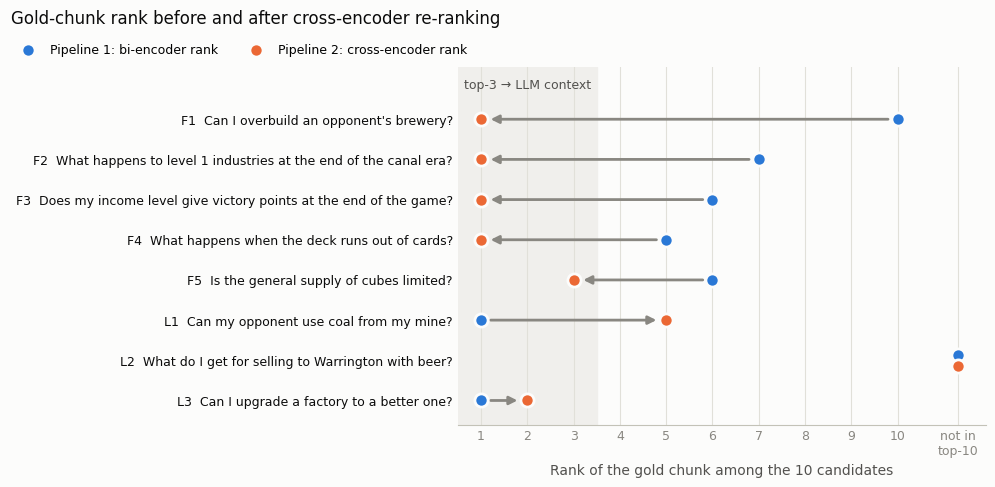

In [20]:
# Dumbbell chart: where the gold chunk sits under each pipeline (rank 1 = best, shaded area = context sent to the LLM)
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
C_BI, C_CE = "#2a78d6", "#eb6834"          # categorical slots 1-2 (validated colour-blind safe on this surface)
NOT_RETRIEVED = 11.3                       # x position used for "not in the top-10"

fig, ax = plt.subplots(figsize=(10, 5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axvspan(0.5, 3.5, color="#f0efec", zorder=0)
ax.text(2.0, -0.85, "top-3 → LLM context", ha="center", va="center", fontsize=9, color=INK_2)

labels = [f"{r['case']}  {r['query']}" for r in all_case_results]
for y, r in enumerate(all_case_results):
    x1 = r["gold_rank_p1"] or NOT_RETRIEVED
    x2 = r["gold_rank_p2"] or NOT_RETRIEVED
    if x1 != x2:
        ax.annotate("", xy=(x2, y), xytext=(x1, y),
                    arrowprops=dict(arrowstyle="-|>", color=MUTED, lw=2, shrinkA=7, shrinkB=7, mutation_scale=12))
    dy = 0.14 if x1 == x2 else 0.0          # same rank under both pipelines: show both markers side by side
    ax.scatter(x1, y - dy, s=90, color=C_BI, edgecolor=SURFACE, linewidth=2, zorder=3,
               label="Pipeline 1: bi-encoder rank" if y == 0 else None)
    ax.scatter(x2, y + dy, s=90, color=C_CE, edgecolor=SURFACE, linewidth=2, zorder=4,
               label="Pipeline 2: cross-encoder rank" if y == 0 else None)

ax.set_yticks(range(len(labels)), labels, fontsize=9, color=INK)
ax.set_ylim(len(labels) - 0.4, -1.3)
ax.set_xticks(list(range(1, 11)) + [NOT_RETRIEVED], [str(i) for i in range(1, 11)] + ["not in\ntop-10"], color=MUTED, fontsize=9)
ax.set_xlim(0.5, 11.9)
ax.set_xlabel("Rank of the gold chunk among the 10 candidates", color=INK_2)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(length=0)
plt.tight_layout(rect=(0, 0, 1, 0.88))
fig.text(0.01, 0.965, "Gold-chunk rank before and after cross-encoder re-ranking", color=INK, fontsize=12, va="top")
fig.legend(loc="upper left", bbox_to_anchor=(0.003, 0.92), ncol=2, frameon=False, fontsize=9)
plt.savefig(f"{RESULTS_DIR}/rank_shifts.png", dpi=160, facecolor=SURFACE)
plt.show()

### 8.3 Answer 1 vs. Answer 2 side by side

In [21]:
answers_df = pd.DataFrame([{
    "case": r["case"], "query": r["query"],
    "answer_1_baseline": r["answer_1"], "answer_2_reranked": r["answer_2"], "expected_from_rulebook": r["expected"],
} for r in all_case_results])

with pd.option_context("display.max_colwidth", None):
    display(answers_df.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))

case,query,answer_1_baseline,answer_2_reranked,expected_from_rulebook
F1,Can I overbuild an opponent's brewery?,"The rulebook does not address the possibility of overbuilding an opponent's brewery. Therefore, based on the provided excerpts, this question cannot be answered.","No, you cannot overbuild an opponent's brewery. Overbuilding is only allowed for opponent-owned Coal Mines or Iron Works, as stated in Excerpt 1. Breweries are not listed as eligible industries for overbuilding.","No. An opponent's tile can only be overbuilt if it is a Coal Mine or an Iron Works, and only when no cubes of that resource remain anywhere on the board, including its Market."
F2,What happens to level 1 industries at the end of the canal era?,"At the end of the Canal Era, level 1 industries remain on the board and can be upgraded or replaced during the Rail Era if you perform a Build action. However, if you do not build or develop at least one Coal Mine and one Iron Works during the Canal Era, you will need to use a Develop action during the Rail Era to clear these industries.","At the end of the Canal Era, all level 1 Industry tiles are removed from the board and returned to the box. Level 2 or greater Industry tiles remain on the board.",They are removed from the board (not from Player Mats) and returned to the box; level 2+ tiles stay on the board.
F3,Does my income level give victory points at the end of the game?,"No, your income level does not give victory points at the end of the game. According to Excerpt 2, income level gives victory points only in the introductory game, specifically as part of the Income level scoring rule, and only if the game is not the final round. In the full game, there is no mention of income level providing victory points at the end.","Yes, your income level gives victory points at the end of the game. According to the rulebook, you score VPs equal to your income level, and if your income level is negative, you lose VPs.",No. In the full game income level is not worth VPs (it only breaks ties). Only the introductory (Canal-Era-only) variant scores VPs equal to income level.
F4,What happens when the deck runs out of cards?,"When the deck runs out of cards, the rounds continue until both the Draw Deck and players’ Hands are exhausted. After that, the Rail Era scoring is performed to determine the winner.","When the Draw Deck is exhausted, players' Hands decrease each round until they have no cards left. The era continues until both the Draw Deck and players’ Hands are exhausted.","You stop refilling your hand, so hands shrink each round until empty; the era ends after the round in which all players play their last cards (after the Canal Era the discard piles are shuffled into a new Draw Deck)."
F5,Is the general supply of cubes limited?,"Yes, the general supply of cubes is limited. The rulebook states there are 18 Iron cubes and 30 Coal cubes, and consumed iron cubes are placed back into the General Supply, implying the supply is finite and managed.","No, the general supply of cubes is not limited. The General Supply is limitless.","No. The General Supply is limitless; if you run out of a resource, represent it with something else."
L1,Can my opponent use coal from my mine?,"Yes, your opponent can use coal from your mine because the rule states that coal can be consumed from ""the closest (fewest Link tiles distant) connected unflipped Coal Mine F (owned by any player)."" This means any player, including opponents, can access coal from a mine they own or that is connected to their network.","No, your opponent cannot use coal from your mine. According to the rules, only players who are connected to a Coal Mine can purchase coal from the Coal Market, and coal from a mine belongs to the owner of that mine. Since your opponent does not own the mine, they cannot access or use coal from it.","Yes. Coal is consumed (for free) from the closest connected unflipped Coal Mine, owned by any player."
L2,What do I get for sell

## 9. Broader check over all 76 labelled questions

This uses retrieval only (no LLM). It shows how often each pipeline places the gold chunk in the top-3 that the LLM sees, and how often re-ranking helps or hurts.

* **Hit@k:** the gold chunk is within the first *k*.
* **MRR@10:** the mean of 1/rank (0 if the gold chunk is not in the top-10).
* **Recall@10:** identical for both pipelines by construction, because re-ranking only reorders the same 10 candidates.

In [22]:
EVAL_QUERIES = [
    # (question, [evidence phrases copied verbatim from the rulebook])
    ("How many actions does each player take on their turn?", ["On your turn, perform a total of 2 actions"]),
    ("How many actions do I get on the very first turn of the game?", ["each player performs only 1 action"]),
    ("Can I sell my industry tiles to get cash?", ["for any reason other than paying for a shortfall", "each being worth half of its cost"]),
    ("Can I demolish my own buildings to raise money whenever I want?", ["for any reason other than paying for a shortfall", "each being worth half of its cost"]),
    ("What happens if a player goes bankrupt and cannot pay?", ["If you have a shortfall when paying", "If you have no way to pay a shortfall"]),
    ("What is the penalty if I cannot pay my negative income?", ["lose 1 VP (if possible) for each"]),
    ("Is there a penalty for going into debt?", ["lose 1 VP (if possible) for each"]),
    ("How do I build a railway between two towns?", ["Network During Rail Era", "To perform the Network action"]),
    ("How much does it cost to build railroad tracks?", ["You may build 1 rail Link for £5"]),
    ("How much does it cost to dig a canal?", ["maximum of 1 canal Link for £3"]),
    ("Can I build rail links during the canal era?", ["Network During Canal Era: • You may not build rail Links"]),
    ("Is it forbidden to build canals in the rail era?", ["You may not build canal Links"]),
    ("Can I overbuild an opponent's brewery?", ["You may Overbuild only a Coal Mine or an Iron Works", "Overbuild opponents’ Coal Mines/Iron Works"]),
    ("Can I upgrade a factory to a better one?", ["This is known as Overbuilding"]),
    ("What happens to resources on my own tile when I overbuild it?", ["If there are any iron / coal / beer on the tile being replaced"]),
    ("Do opponents lose points when their industry is overbuilt?", ["Players do not lose previously gained income or VPs"]),
    ("Do I need a connection to buy iron from the Iron Market?", ["does not need a connection to a source of iron", "consume coal (but not iron)"]),
    ("Is coal from the market available without a connection to a port?", ["This requires a connection to a", "consume coal (but not iron)"]),
    ("Must coal come from the nearest mine?", ["The closest (fewest Link tiles distant)"]),
    ("Does iron have to come from the closest iron works?", ["it does not have to be the closest"]),
    ("Do I have to pay for coal taken from an opponent's coal mine?", ["Consuming coal in this way is free"]),
    ("Do I have to pay for iron from another player's iron works?", ["Consuming iron in this way is free"]),
    ("Can my opponent use coal from my mine?", ["connected unflipped Coal Mine"]),
    ("Can I sell coal to the market after the turn I built the mine?", ["never sold to their Markets in later turns"]),
    ("Can I sell a coal mine's cubes to the market later?", ["never sold to their Markets in later turns"]),
    ("How do I make money from my iron works?", ["For each cube moved, collect the corresponding amount of money"]),
    ("Can I use merchant beer to build two rail links?", ["(not a Merchant beer)"]),
    ("Is a merchant beer allowed when networking with two rails?", ["(not a Merchant beer)"]),
    ("Do I need to be connected to my own brewery to use its beer?", ["These do not need to be connected", "do not need to be connected to consume your own"]),
    ("Can I buy beer from the market?", ["Beer may be consumed from any of the following sources"]),
    ("Can I sell cotton if I have no beer?", ["cannot perform the Sell action if you cannot consume the required beer", "Beer (usually)"]),
    ("Is beer needed to sell goods?", ["Selling requires"]),
    ("How do I sell my manufactured goods to a market?", ["Performing the Sell action allows you"]),
    ("What do potteries need to be sold?", ["Performing the Sell action allows you"]),
    ("What does the Gloucester merchant bonus do?", ["Develop (Gloucester)"]),
    ("What do I get for selling to Warrington with beer?", ["Money (Warrington)"]),
    ("Can I build a level 1 Pottery in the Rail Era?", ["level 1 Pottery tile may be built during the Rail Era"]),
    ("Can I develop a pottery tile with a lightbulb icon?", ["icon may not be developed"]),
    ("What is a lightbulb icon?", ["icon may not be developed"]),
    ("Can I remove a lightbulb pottery tile with the Gloucester bonus?", ["You cannot remove a Pottery tile showing a"]),
    ("Is there a limit on how many loans I can take?", ["income level below -10"]),
    ("Is it allowed to take a loan when my income level is -9?", ["income level below -10"]),
    ("Can I borrow money from the bank?", ["Performing the Loan action allows you to acquire more money"]),
    ("Do I have to repay my debts to the bank?", ["Loans are never repaid"]),
    ("Do I collect income after the last round?", ["Income is not collected at the end of the final round"]),
    ("What is the maximum income level?", ["above level 30"]),
    ("Does my income level give victory points at the end of the game?", ["income level at the end of the game is not worth VPs"]),
    ("Can I take a Scout action when I already hold a wild card?", ["already have a Wild card in your Hand"]),
    ("Can I pass instead of taking an action and keep my cards?", ["must still discard a card for each action you pass"]),
    ("Which locations have no merchant tiles in a two player game?", ["In a 2 player game, no Merchant tiles"]),
    ("Can I use a Wild Location card to build a farm brewery?", ["This does not include the 2 Farm Breweries", "using a Brewery Industry card or a Wild Industry card"]),
    ("Can I build a second link to the farm brewery near Worcester?", ["nor may it be placed there"]),
    ("Can I build a factory on a farm?", ["these are Farm Breweries"]),
    ("How many industry tiles can I place in the same town during the canal era?", ["maximum of 1 Industry tile per location", "maximum of 1 of their Industry tiles in each location"]),
    ("Can I build a mill in the same town as another player's mill during the canal period?", ["may have an Industry tile in the same location as other players"]),
    ("Can I place more than one industry per town in the railway age?", ["You may build multiple Industry tiles in each location"]),
    ("Can I build a coal mine in a location outside my network?", ["even if the location is not a part of your network", "unless you use that specific Location card"]),
    ("Is building a cotton mill allowed anywhere on the map?", ["in a location that is a part of your network", "A location must be a part of your network"]),
    ("What happens to level 1 industries at the end of the canal era?", ["Remove all level 1 Industry tiles from the board"]),
    ("Do unflipped industries score points?", ["do not score"]),
    ("When is a brewery flipped?", ["Coal Mines, Iron Works, and Breweries: Flip"]),
    ("Do I keep my link tiles after they are scored?", ["Remove Link tiles from the board as they are scored"]),
    ("How are railways scored?", ["Score Canal/Rail Links"]),
    ("How are canals scored?", ["Score Canal/Rail Links"]),
    ("Can a player go above 100 victory points?", ["If you score more than 100 VPs"]),
    ("Who wins if two players have the same score?", ["Ties are broken"]),
    ("When does the game end?", ["following the end of the Rail Era", "Each era ends following the round"]),
    ("What happens when the deck runs out of cards?", ["Once the Draw Deck has been exhausted"]),
    ("How many cards does each player hold?", ["Draw 8 cards from the Draw Deck", "refill your Hand back up to 8 cards"]),
    ("Should I show my cards to other players?", ["Do not reveal your Hand"]),
    ("How much money does each player start with?", ["Take £17 from the Bank"]),
    ("Is the general supply of cubes limited?", ["The General Supply is limitless"]),
    ("Who controls the order of play?", ["spent the least money"]),
    ("What happens to the money I spend on my turn?", ["Place all money spent during your turn on top of your Character tile"]),
    ("Can my opponent's links connect me to a merchant?", ["(owned by any player) from one location"]),
    ("Do I need to own the railway line to move goods along it?", ["(owned by any player) from one location"]),
]

In [23]:
eval_rows = []
for q, evidence in EVAL_QUERIES:
    gold = gold_ids(evidence)
    cands = baseline_retrieve(q)
    rr = rerank(q, cands)
    eval_rows.append({
        "query": q, "gold_chunks": gold,
        "rank_p1": min((c["bi_rank"] for c in cands if c["chunk_id"] in gold), default=None),
        "rank_p2": min((c["ce_rank"] for c in rr if c["chunk_id"] in gold), default=None),
    })
eval_df = pd.DataFrame(eval_rows)
eval_df[["rank_p1", "rank_p2"]] = eval_df[["rank_p1", "rank_p2"]].astype("Int64")   # <NA> = not in the top-10


def retrieval_metrics(ranks):
    r = ranks.astype(float).fillna(np.inf)
    return {"Hit@1": (r <= 1).mean(), "Hit@3": (r <= 3).mean(), "MRR@10": (1 / r).mean(), "Recall@10": (r <= 10).mean()}


metrics_df = pd.DataFrame({
    "Pipeline 1 (bi-encoder)": retrieval_metrics(eval_df["rank_p1"]),
    "Pipeline 2 (+ cross-encoder)": retrieval_metrics(eval_df["rank_p2"]),
}).T.round(3)
display(metrics_df)

in3_p1 = eval_df["rank_p1"].fillna(99) <= TOP_K_CONTEXT
in3_p2 = eval_df["rank_p2"].fillna(99) <= TOP_K_CONTEXT
moves = pd.Series({
    "gold moved INTO the top-3 by re-ranking": int((~in3_p1 & in3_p2).sum()),
    "gold pushed OUT of the top-3 by re-ranking": int((in3_p1 & ~in3_p2).sum()),
    "gold in top-3 under both": int((in3_p1 & in3_p2).sum()),
    "gold in neither top-3": int((~in3_p1 & ~in3_p2).sum()),
}, name=f"questions (of {len(eval_df)})")
display(moves.to_frame())

print("Questions whose gold chunk crossed the top-3 boundary:")
eval_df[in3_p1 != in3_p2].sort_values("rank_p1")

,Hit@1,Hit@3,MRR@10,Recall@10
Pipeline 1 (bi-encoder),0.605,0.816,0.724,0.947
Pipeline 2 (+ cross-encoder),0.697,0.882,0.794,0.947


,questions (of 76)
gold moved INTO the top-3 by re-ranking,8
gold pushed OUT of the top-3 by re-ranking,3
gold in top-3 under both,59
gold in neither top-3,6


Questions whose gold chunk crossed the top-3 boundary:


,query,gold_chunks,rank_p1,rank_p2
22,Can my opponent use coal from my mine?,[31],1,5
20,Do I have to pay for coal taken from an opponent's coal mine?,[31],2,5
70,How much money does each player start with?,[17],2,4
33,What do potteries need to be sold?,[44],4,3
67,What happens when the deck runs out of cards?,[21],5,1
13,Can I upgrade a factory to a better one?,[43],5,2
73,What happens to the money I spend on my turn?,[21],5,2
46,Does my income level give victory points at the end of the game?,[55],6,1
71,Is the general supply of cubes limited?,[16],6,3
58,What happens to level 1 industries at the end of the canal era?,[27],7,1


## 10. Latency profiling

Timings use `time.perf_counter()` after a warm-up, over all 76 questions × 5 repeats.
The model calls return NumPy arrays, so each timed GPU call includes the device→host synchronisation.
Retrieval and re-ranking are timed on both the GPU and the CPU.
LLM time comes from the 16 generations in section 8 and is reported separately, because it depends on answer length.

In [24]:
def time_ms(fn, *args, **kwargs):
    t0 = perf_counter()
    out = fn(*args, **kwargs)
    return out, (perf_counter() - t0) * 1e3


def profile_retrieval(bi_model, ce_model, device_label, queries, repeats=5):
    for q in queries[:5]:                                       # warm-up (CUDA kernels, caches)
        bi_model.encode([q]); ce_model.predict([(q, chunk_texts[0])] * TOP_K_RETRIEVE)
    rows = []
    for _ in range(repeats):
        for q in queries:
            q_emb, t_embed = time_ms(bi_model.encode, [q], normalize_embeddings=True, convert_to_numpy=True)
            (_, ids), t_search = time_ms(index.search, q_emb.astype("float32"), TOP_K_RETRIEVE)
            pairs = [(q, chunk_texts[i]) for i in ids[0]]
            ce_scores, t_ce = time_ms(ce_model.predict, pairs, batch_size=len(pairs))
            _, t_sort = time_ms(np.argsort, -ce_scores)
            rows.append({"device": device_label, "query_embedding": t_embed, "faiss_search": t_search,
                         "cross_encoder_10_pairs": t_ce + t_sort})
    df = pd.DataFrame(rows)
    df["pipeline_1_retrieval"] = df["query_embedding"] + df["faiss_search"]
    df["pipeline_2_retrieval"] = df["pipeline_1_retrieval"] + df["cross_encoder_10_pairs"]
    return df


eval_queries = [q for q, _ in EVAL_QUERIES]
lat_frames = [profile_retrieval(bi_encoder, cross_encoder, DEVICE.upper(), eval_queries)]
if DEVICE == "cuda":   # also profile on CPU, the common deployment target for small encoders
    bi_cpu = SentenceTransformer(BI_ENCODER_NAME, device="cpu")
    ce_cpu = CrossEncoder(CROSS_ENCODER_NAME, device="cpu")
    lat_frames.append(profile_retrieval(bi_cpu, ce_cpu, "CPU", eval_queries))
lat_df = pd.concat(lat_frames, ignore_index=True)

stages = ["query_embedding", "faiss_search", "pipeline_1_retrieval", "cross_encoder_10_pairs", "pipeline_2_retrieval"]
latency_table = (lat_df.melt(id_vars="device", value_vars=stages, var_name="stage", value_name="ms")
                 .groupby(["device", "stage"], sort=False)["ms"]
                 .agg(mean="mean", median="median", p95=lambda s: s.quantile(0.95))
                 .round(2))
print(f"Retrieval latency per query in ms (n = {len(eval_queries)} questions x 5 repeats per device)")
display(latency_table)

overhead = (lat_df.groupby("device")["pipeline_2_retrieval"].median() / lat_df.groupby("device")["pipeline_1_retrieval"].median()).round(1)
print("Pipeline 2 / Pipeline 1 retrieval time (median):", overhead.to_dict())

Retrieval latency per query in ms (n = 76 questions x 5 repeats per device)


,,mean,median,p95
device,stage,,,
CUDA,query_embedding,4.61,4.26,6.57
CPU,query_embedding,8.28,8.21,8.91
CUDA,faiss_search,0.03,0.02,0.03
CPU,faiss_search,0.03,0.03,0.03
CUDA,pipeline_1_retrieval,4.64,4.28,6.60
CPU,pipeline_1_retrieval,8.31,8.24,8.94
CUDA,cross_encoder_10_pairs,9.97,9.65,11.61
CPU,cross_encoder_10_pairs,96.57,92.03,115.71
CUDA,pipeline_2_retrieval,14.61,14.24,17.74


Pipeline 2 / Pipeline 1 retrieval time (median): {'CPU': 12.2, 'CUDA': 3.3}


In [25]:
# End-to-end view on the 8 cases from section 8 (single runs with the LLM on the main device)
e2e = pd.DataFrame([{
    "case": r["case"],
    "retrieval_ms": r["timings"]["retrieval_ms"], "rerank_ms": r["timings"]["rerank_ms"],
    "llm_1_ms": r["timings"]["llm_1_ms"], "llm_2_ms": r["timings"]["llm_2_ms"],
    "tokens_1": r["answer_1_tokens"], "tokens_2": r["answer_2_tokens"],
} for r in all_case_results])
e2e["pipeline_1_total_ms"] = e2e["retrieval_ms"] + e2e["llm_1_ms"]
e2e["pipeline_2_total_ms"] = e2e["retrieval_ms"] + e2e["rerank_ms"] + e2e["llm_2_ms"]
e2e["llm_ms_per_token"] = (e2e["llm_1_ms"] + e2e["llm_2_ms"]) / (e2e["tokens_1"] + e2e["tokens_2"])
display(e2e.round(1))

e2e_summary = pd.DataFrame({
    "Pipeline 1 (baseline)": {"retrieval": e2e.retrieval_ms.mean(), "re-ranking": 0.0,
                              "LLM generation": e2e.llm_1_ms.mean(), "total": e2e.pipeline_1_total_ms.mean()},
    "Pipeline 2 (re-ranking)": {"retrieval": e2e.retrieval_ms.mean(), "re-ranking": e2e.rerank_ms.mean(),
                                "LLM generation": e2e.llm_2_ms.mean(), "total": e2e.pipeline_2_total_ms.mean()},
}).T.round(1)
print(f"Mean end-to-end latency in ms ({DEVICE.upper()}, {len(e2e)} queries; models already warm from section 7):")
display(e2e_summary)

,case,retrieval_ms,rerank_ms,llm_1_ms,llm_2_ms,tokens_1,tokens_2,pipeline_1_total_ms,pipeline_2_total_ms,llm_ms_per_token
0,F1,7.4,10.8,1404.5,2029.2,31,46,1411.9,2047.4,44.6
1,F2,5.7,10.1,3255.4,1849.7,74,38,3261.1,1865.4,45.6
2,F3,5.2,9.3,3181.7,1953.8,76,45,3186.9,1968.3,42.4
3,F4,6.9,9.4,1697.1,1608.6,38,36,1703.9,1624.9,44.7
4,F5,5.4,10.3,2136.1,842.4,49,18,2141.5,858.1,44.5
5,L1,6.5,10.2,2940.8,2758.4,68,65,2947.4,2775.1,42.9
6,L2,5.5,10.1,1820.0,3703.2,41,90,1825.5,3718.8,42.2
7,L3,5.5,9.4,1872.9,1343.6,45,30,1878.4,1358.5,42.9


Mean end-to-end latency in ms (CUDA, 8 queries; models already warm from section 7):


,retrieval,re-ranking,LLM generation,total
Pipeline 1 (baseline),6.0,0.0,2288.5,2294.6
Pipeline 2 (re-ranking),6.0,9.9,2011.1,2027.1


## 11. Scaling experiment

This measures what one query costs as the collection grows:

* **(a)** Bi-encoder side: embed the query once, then run an exact FAISS search over *N* vectors. Random unit vectors of the same dimension stand in for a large corpus.
* **(b)** Cross-encoder side: score *N* (query, chunk) pairs, which is what a cross-encoder-only system would have to do for every query. The rulebook's chunks are repeated to reach *N*; cost depends on sequence length, not content.

Large sizes are **extrapolated linearly** from the measured throughput and marked `measured = False`.
The bi-encoder's one-off cost of indexing the corpus is listed separately.

In [26]:
probe_query = FAILURE_CASES[0]["query"]
q_emb = bi_encoder.encode([probe_query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
t_query_embed = statistics.median(time_ms(bi_encoder.encode, [probe_query], normalize_embeddings=True)[1] for _ in range(20))
dim = chunk_embeddings.shape[1]
rng = np.random.default_rng(0)

# (a) query embedding + exact FAISS search over N vectors (median of 20 searches)
faiss_rows = []
for n in [len(chunks), 1_000, 10_000, 100_000, 1_000_000]:
    if n == len(chunks):
        vecs = chunk_embeddings
    else:
        vecs = rng.standard_normal((n, dim), dtype=np.float32)
        faiss.normalize_L2(vecs)
    idx = faiss.IndexFlatIP(dim)
    idx.add(vecs)
    idx.search(q_emb, TOP_K_RETRIEVE)                        # warm-up
    t_search = statistics.median(time_ms(idx.search, q_emb, TOP_K_RETRIEVE)[1] for _ in range(20))
    faiss_rows.append({"corpus_size": n, "bi_encoder_query_ms": t_query_embed + t_search, "measured": True})
    del idx, vecs

# (b) cross-encoder over all N pairs, measured on small N, extrapolated from throughput beyond that
def ce_scaling(model, device_label, sizes, extrapolate_to, batch_size):
    rows = []
    model.predict([(probe_query, chunk_texts[0])] * 8)       # warm-up
    for n in sizes:
        pairs = [(probe_query, chunk_texts[i % len(chunk_texts)]) for i in range(n)]
        reps = 5 if n <= 1_000 else 1                        # small sizes are noisy: median of 5 runs
        t = statistics.median(time_ms(model.predict, pairs, batch_size=batch_size)[1] for _ in range(reps))
        rows.append({"corpus_size": n, "device": device_label, "cross_encoder_all_pairs_ms": t, "measured": True})
    pairs_per_s = sizes[-1] / (rows[-1]["cross_encoder_all_pairs_ms"] / 1e3)
    for n in extrapolate_to:
        rows.append({"corpus_size": n, "device": device_label,
                     "cross_encoder_all_pairs_ms": n / pairs_per_s * 1e3, "measured": False})
    print(f"Cross-encoder throughput on {device_label}: {pairs_per_s:,.0f} pairs/s")
    return rows

ce_rows = ce_scaling(cross_encoder, DEVICE.upper(), [TOP_K_RETRIEVE, len(chunks), 1_000, 5_000, 20_000],
                     [100_000, 1_000_000], batch_size=128)
if DEVICE == "cuda":
    ce_rows += ce_scaling(ce_cpu, "CPU", [TOP_K_RETRIEVE, len(chunks), 500],
                          [1_000, 10_000, 100_000, 1_000_000], batch_size=32)

faiss_df = pd.DataFrame(faiss_rows)
ce_df = pd.DataFrame(ce_rows)

# display table: ms per query, "*" marks values extrapolated from the measured throughput
ce_cells = ce_df.assign(cell=[f"{ms:,.1f}" + ("" if m else " *")
                              for ms, m in zip(ce_df.cross_encoder_all_pairs_ms, ce_df.measured)])
scaling_table = (ce_cells.pivot(index="corpus_size", columns="device", values="cell")
                 .add_prefix("cross-encoder over all N pairs, ")
                 .join(faiss_df.set_index("corpus_size")["bi_encoder_query_ms"].map("{:,.1f}".format)
                       .rename("bi-encoder: embed query + FAISS search"), how="outer")
                 .fillna(""))
print("Latency per query in ms (* = extrapolated)")
display(scaling_table)

# One-off indexing cost of the bi-encoder, measured on 2,000 chunks with the warmed-up model
index_texts = [chunk_texts[i % len(chunk_texts)] for i in range(2_000)]
_, t_index = time_ms(bi_encoder.encode, index_texts, batch_size=128, normalize_embeddings=True)
per_chunk_index_ms = t_index / len(index_texts)
print(f"One-off bi-encoder indexing cost: {per_chunk_index_ms:.2f} ms/chunk on {DEVICE.upper()} "
      f"→ ~{per_chunk_index_ms * 1e6 / 1e3 / 60:.1f} min to embed 1M chunks (paid once, offline, not per query)")

Cross-encoder throughput on CUDA: 2,156 pairs/s
Cross-encoder throughput on CPU: 118 pairs/s
Latency per query in ms (* = extrapolated)


,"cross-encoder over all N pairs, CPU","cross-encoder over all N pairs, CUDA",bi-encoder: embed query + FAISS search
corpus_size,,,
10,171.7,56.9,
59,821.2,78.3,4.3
500,"4,247.3",,
1000,"8,494.6 *",577.9,4.3
5000,,"2,437.3",
10000,"84,945.6 *",,4.6
20000,,"9,276.0",
100000,"849,455.6 *","46,379.8 *",11.5
1000000,"8,494,556.4 *","463,798.4 *",70.8


One-off bi-encoder indexing cost: 0.55 ms/chunk on CUDA → ~9.2 min to embed 1M chunks (paid once, offline, not per query)


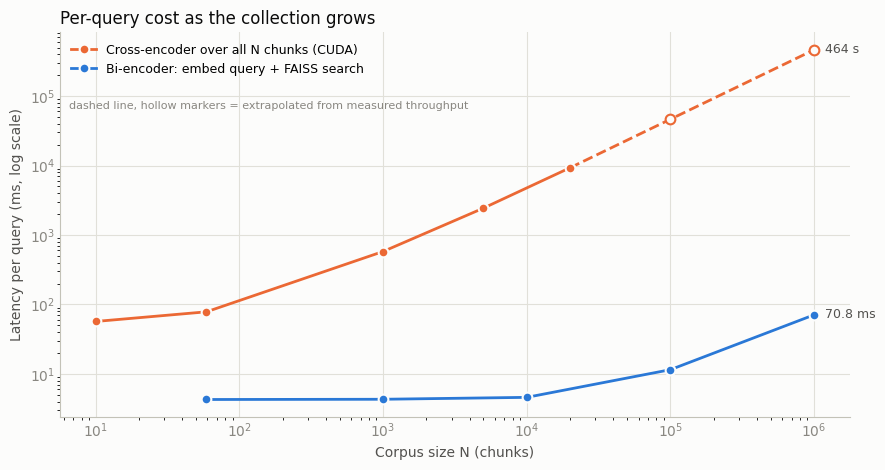

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

def plot_series(df, ycol, color, label):
    m, e = df[df.measured], df[~df.measured]
    ax.plot(m.corpus_size, m[ycol], color=color, lw=2, marker="o", ms=7, mec=SURFACE, mew=1.5, label=label)
    if len(e):
        bridge = pd.concat([m.tail(1), e])
        ax.plot(bridge.corpus_size, bridge[ycol], color=color, lw=2, ls="--", zorder=1)   # dashed link, no markers
        ax.plot(e.corpus_size, e[ycol], ls="none", marker="o", ms=7, mfc=SURFACE, mec=color, mew=1.5)   # hollow = extrapolated
    last = df.iloc[-1]
    ax.annotate(f"{last[ycol] / 1e3:,.0f} s" if last[ycol] >= 1e3 else f"{last[ycol]:.1f} ms",
                (last.corpus_size, last[ycol]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK_2)

ce_main = ce_df[ce_df.device == DEVICE.upper()].sort_values("corpus_size")
plot_series(ce_main, "cross_encoder_all_pairs_ms", C_CE, f"Cross-encoder over all N chunks ({DEVICE.upper()})")
plot_series(faiss_df, "bi_encoder_query_ms", C_BI, "Bi-encoder: embed query + FAISS search")

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Corpus size N (chunks)", color=INK_2)
ax.set_ylabel("Latency per query (ms, log scale)", color=INK_2)
ax.grid(color=GRID, linewidth=0.8, which="major"); ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
for side in ("left", "bottom"):
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.text(0.012, 0.80, "dashed line, hollow markers = extrapolated from measured throughput", transform=ax.transAxes,
        ha="left", fontsize=8, color=MUTED)
ax.set_title("Per-query cost as the collection grows", color=INK, fontsize=12, loc="left")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/scaling.png", dpi=160, facecolor=SURFACE)
plt.show()

## 12. Export results

Writes the tables behind the report to `results/`.

In [28]:
chunk_df[["chunk_id", "page", "words", "text"]].to_csv(f"{RESULTS_DIR}/chunks.csv", index=False)
rank_shift_df.to_csv(f"{RESULTS_DIR}/rank_shifts.csv", index=False)
answers_df.to_csv(f"{RESULTS_DIR}/answers.csv", index=False)
eval_df.to_csv(f"{RESULTS_DIR}/eval_76_questions.csv", index=False)
metrics_df.to_csv(f"{RESULTS_DIR}/retrieval_metrics.csv")
latency_table.to_csv(f"{RESULTS_DIR}/latency_retrieval.csv")
e2e.round(2).to_csv(f"{RESULTS_DIR}/latency_end_to_end.csv", index=False)
ce_df.round(3).to_csv(f"{RESULTS_DIR}/scaling_cross_encoder.csv", index=False)
faiss_df.round(3).to_csv(f"{RESULTS_DIR}/scaling_bi_encoder.csv", index=False)

# full per-case detail: the 10 candidates with both scores, both contexts and both answers
with open(f"{RESULTS_DIR}/case_details.json", "w", encoding="utf-8") as f:
    json.dump([{k: v for k, v in r.items()} for r in [sanity] + all_case_results], f, indent=2, ensure_ascii=False)

for name in sorted(os.listdir(RESULTS_DIR)):
    print(f"{RESULTS_DIR}/{name}")

results/answers.csv
results/case_details.json
results/chunks.csv
results/eval_76_questions.csv
results/latency_end_to_end.csv
results/latency_retrieval.csv
results/rank_shifts.csv
results/rank_shifts.png
results/retrieval_metrics.csv
results/scaling.png
results/scaling_bi_encoder.csv
results/scaling_cross_encoder.csv
